
# Tugas Analisis Web Structure Mining

Bagian ini berisi kode inisialisasi untuk membuat graf berarah (Directed) dan graf tidak berarah (Undirected) dengan 5 vertex (A, B, C, D, E) menggunakan library **NetworkX**.

Agar perhitungan lintasan terpendek (*shortest path*) dan diameter dapat dilakukan tanpa error, struktur graf dirancang sedemikian rupa sehingga bersifat *strongly connected* (saling terhubung kuat) untuk Directed Graph.


In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Inisialisasi Vertex
vertices = ['A', 'B', 'C', 'D', 'E']

# 2. Definisikan hubungan (Edges) untuk Directed Graph
# Relasi dibuat melingkar dengan beberapa bypass agar Strongly Connected
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),  # Siklus utama
    ('A', 'C'), ('C', 'E'), ('D', 'B')                       # Hubungan bypass
]

# Membuat Directed Graph (DiGraph)
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

# 3. Definisikan hubungan (Edges) untuk Undirected Graph
# Menggunakan struktur relasi yang sama (tanpa arah panah)
undirected_edges = directed_edges

# Membuat Undirected Graph (Graph)
UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(undirected_edges)

print("Graf berhasil diinisialisasi!")
print(f"Directed Graph: {DG.number_of_nodes()} node, {DG.number_of_edges()} edge (Strongly Connected: {nx.is_strongly_connected(DG)})")
print(f"Undirected Graph: {UG.number_of_nodes()} node, {UG.number_of_edges()} edge (Connected: {nx.is_connected(UG)})")

Graf berhasil diinisialisasi!
Directed Graph: 5 node, 8 edge (Strongly Connected: True)
Undirected Graph: 5 node, 8 edge (Connected: True)



## A. Visualisasi Graf
Berikut adalah pembuatan dua gambar terpisah untuk memvisualisasikan **Directed Graph** dan **Undirected Graph** dengan layout yang rapi dan warna node yang berbeda.


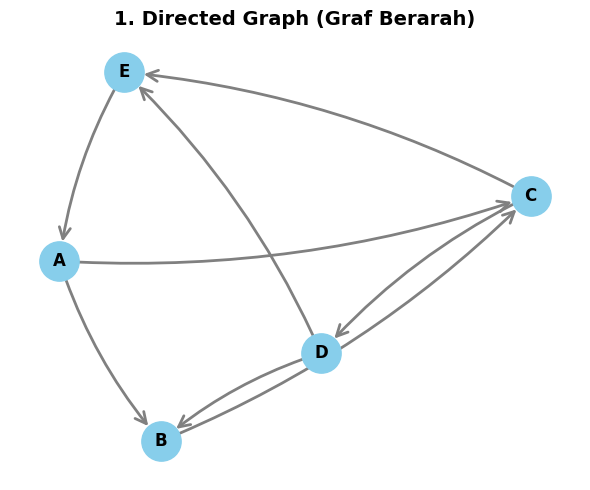

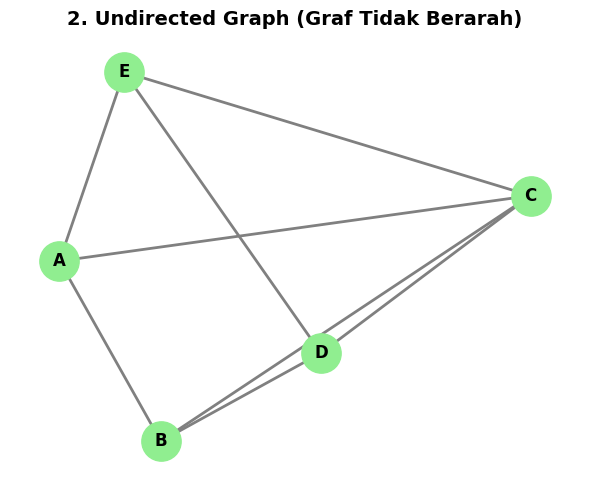

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

# Memastikan variabel graf tersedia di dalam namespace sel ini
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

# Mengatur posisi node agar konsisten
pos = nx.spring_layout(DG, seed=42)

# 1. Visualisasi Directed Graph dengan arrow perbaikan bug
plt.figure(figsize=(6, 5))
nx.draw_networkx_nodes(DG, pos, node_color='skyblue', node_size=800)
nx.draw_networkx_labels(DG, pos, font_size=12, font_family='sans-serif', font_weight='bold')
nx.draw_networkx_edges(
    DG, pos,
    arrowstyle='->',
    arrowsize=20,
    edge_color='gray',
    width=2,
    connectionstyle="arc3,rad=0.1",
    node_size=800
)
plt.title("1. Directed Graph (Graf Berarah)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('directed_graph.png', dpi=300)
plt.show()

# 2. Visualisasi Undirected Graph
plt.figure(figsize=(6, 5))
nx.draw_networkx_nodes(UG, pos, node_color='lightgreen', node_size=800)
nx.draw_networkx_labels(UG, pos, font_size=12, font_family='sans-serif', font_weight='bold')
nx.draw_networkx_edges(UG, pos, edge_color='gray', width=2, node_size=800) # Tanpa panah
plt.title("2. Undirected Graph (Graf Tidak Berarah)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('undirected_graph.png', dpi=300)
plt.show()


## B. Analisis Directed Graph dan Undirected Graph

### 1. Degree Setiap Vertex
 rumus derajat (Degree) simpul $i$ pada graf tidak berarah adalah:
$$k_i = \sum_{j} A_{ij}$$

Sedangkan pada graf berarah, derajat terbagi menjadi:
- **In-Degree** (jumlah edge masuk): $k_i^{in} = \sum_{j} A_{ji}$
- **Out-Degree** (jumlah edge keluar): $k_i^{out} = \sum_{j} A_{ij}$
- **Total Degree**: $k_i^{total} = k_i^{in} + k_i^{out}$


In [3]:
import networkx as nx
import pandas as pd

# Deklarasi lokal untuk mencegah NameError
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

# Menghitung derajat
ug_degrees = dict(UG.degree())
dg_in_degrees = dict(DG.in_degree())
dg_out_degrees = dict(DG.out_degree())
dg_total_degrees = {node: dg_in_degrees[node] + dg_out_degrees[node] for node in vertices}

# Menampilkan Tabel Terpisah sesuai Prompt
df_ug_degree = pd.DataFrame({
    'Vertex': vertices,
    'Degree (k_i)': [ug_degrees[v] for v in vertices]
})

df_dg_degree = pd.DataFrame({
    'Vertex': vertices,
    'In-Degree (k_in)': [dg_in_degrees[v] for v in vertices],
    'Out-Degree (k_out)': [dg_out_degrees[v] for v in vertices],
    'Total Degree (k_total)': [dg_total_degrees[v] for v in vertices]
})

print("=== Tabel Degree: Undirected Graph ===")
display(df_ug_degree)

print("\n=== Tabel Degree: Directed Graph ===")
display(df_dg_degree)

=== Tabel Degree: Undirected Graph ===


,Vertex,Degree (k_i)
0,A,3
1,B,3
2,C,4
3,D,3
4,E,3



=== Tabel Degree: Directed Graph ===


,Vertex,In-Degree (k_in),Out-Degree (k_out),Total Degree (k_total)
0,A,1,2,3
1,B,2,1,3
2,C,2,2,4
3,D,1,2,3
4,E,2,1,3



### 2. Rata-rata Lintasan Terpendek (Average Shortest Path Length)

**Rumus Perhitungan:**
$$\text{Average Shortest Path Length} = \frac{1}{N(N-1)} \sum_{i \neq j} d(v_i, v_j)$$
Di mana $d(v_i, v_j)$ adalah jarak lintasan terpendek dari vertex $i$ ke $j$, dan total pasangan kemungkinan adalah $N(N-1) = 5 \times 4 = 20$.


In [4]:
import networkx as nx
import pandas as pd

# Deklarasi lokal untuk mencegah NameError
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

# Menampilkan matriks rincian jarak terpendek antar-pasangan simpul
dist_ug = dict(nx.all_pairs_shortest_path_length(UG))
dist_dg = dict(nx.all_pairs_shortest_path_length(DG))

matrix_ug = pd.DataFrame(dist_ug).reindex(index=vertices, columns=vertices)
matrix_dg = pd.DataFrame(dist_dg).reindex(index=vertices, columns=vertices)

total_dist_ug = matrix_ug.values.sum()
total_dist_dg = matrix_dg.values.sum()

print("=== Rincian Jarak Jaringan Undirected Graph ===")
display(matrix_ug)
print(f"Total Akumulasi Jarak (UG) = {total_dist_ug}")
print(f"Average Shortest Path (UG) = {total_dist_ug} / 20 = {total_dist_ug/20:.4f}\n")

print("=== Rincian Jarak Jaringan Directed Graph ===")
display(matrix_dg)
print(f"Total Akumulasi Jarak (DG) = {total_dist_dg}")
print(f"Average Shortest Path (DG) = {total_dist_dg} / 20 = {total_dist_dg/20:.4f}")

=== Rincian Jarak Jaringan Undirected Graph ===


,A,B,C,D,E
A,0,1,1,2,1
B,1,0,1,1,2
C,1,1,0,1,1
D,2,1,1,0,1
E,1,2,1,1,0


Total Akumulasi Jarak (UG) = 24
Average Shortest Path (UG) = 24 / 20 = 1.2000

=== Rincian Jarak Jaringan Directed Graph ===


,A,B,C,D,E
A,0,3,2,2,1
B,1,0,2,1,2
C,1,1,0,2,2
D,2,2,1,0,3
E,2,2,1,1,0


Total Akumulasi Jarak (DG) = 34
Average Shortest Path (DG) = 34 / 20 = 1.7000



**Penjelasan Singkat:**
- Pada **Undirected Graph**, rata-rata lintasan terpendek lebih kecil karena jalur komunikasi antar-node bersifat dua arah (timbal balik tanpa hambatan arah).
- Pada **Directed Graph**, jalurnya lebih panjang karena pergerakan dibatasi oleh arah anak panah, sehingga memerlukan rute memutar untuk mencapai node tertentu.



### 3. Koefisien Klasterisasi (Clustering Coefficient)
rumus Clustering Coefficient lokal untuk simpul $i$ pada Undirected Graph adalah:
$$C_i = \frac{T_i}{k_i(k_i - 1) / 2} = \frac{2 T_i}{k_i(k_i - 1)}$$
Di mana $T_i$ melambangkan jumlah hubungan segitiga aktual di sekitar simpul $i$.

Untuk Directed Graph, NetworkX menggunakan algoritma **Fagiolo (2007)** yang menormalisasi relasi segitiga berarah terhadap semua kemungkinan interaksi berarah.


In [5]:
import networkx as nx
import pandas as pd

# Deklarasi lokal untuk mencegah NameError
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

clust_ug = nx.clustering(UG)
clust_dg = nx.clustering(DG)

df_clust_ug = pd.DataFrame({
    'Vertex': vertices,
    'Sisi Segitiga Riil (Ti)': [nx.triangles(UG, v) for v in vertices],
    'Degree (k)': [UG.degree(v) for v in vertices],
    'Clustering Coeff': [clust_ug[v] for v in vertices]
})

df_clust_dg = pd.DataFrame({
    'Vertex': vertices,
    'Clustering Coeff (Fagiolo)': [clust_dg[v] for v in vertices]
})

print("=== Clustering: Undirected Graph ===")
display(df_clust_ug)
print(f"Average Clustering (UG): {nx.average_clustering(UG):.4f}\n")

print("=== Clustering: Directed Graph ===")
display(df_clust_dg)
print(f"Average Clustering (DG): {nx.average_clustering(DG):.4f}")

=== Clustering: Undirected Graph ===


,Vertex,Sisi Segitiga Riil (Ti),Degree (k),Clustering Coeff
0,A,2,3,0.666667
1,B,2,3,0.666667
2,C,4,4,0.666667
3,D,2,3,0.666667
4,E,2,3,0.666667


Average Clustering (UG): 0.6667

=== Clustering: Directed Graph ===


,Vertex,Clustering Coeff (Fagiolo)
0,A,0.333333
1,B,0.333333
2,C,0.333333
3,D,0.333333
4,E,0.333333


Average Clustering (DG): 0.3333



### 4. Distribusi Derajat (Degree Distribution)
Distribusi derajat merepresentasikan frekuensi kemunculan nilai derajat tertentu di dalam jaringan, dinyatakan dalam $P(k)$.

=== Distribusi Derajat: Undirected Graph ===


,Degree (k),Frekuensi N(k),Probabilitas P(k)
0,3,4,0.8
1,4,1,0.2



=== Distribusi Derajat: Directed Graph (Total Degree) ===


,Degree (k),Frekuensi N(k),Probabilitas P(k)
0,3,4,0.8
1,4,1,0.2


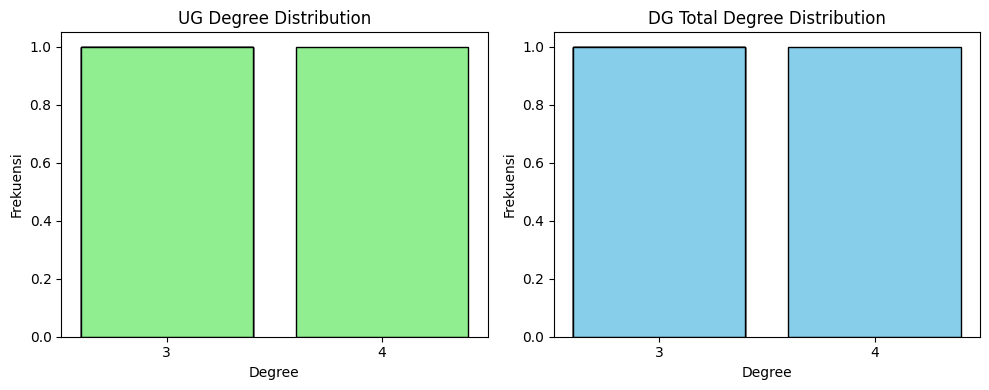

In [6]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

# Deklarasi lokal untuk mencegah NameError
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

ug_degrees = dict(UG.degree())
dg_in_degrees = dict(DG.in_degree())
dg_out_degrees = dict(DG.out_degree())
dg_total_degrees = {node: dg_in_degrees[node] + dg_out_degrees[node] for node in vertices}

# Menghitung tabel frekuensi
def hitung_distribusi_tabel(nilai_derajat):
    df_ser = pd.Series(nilai_derajat).value_counts().sort_index()
    return pd.DataFrame({
        'Degree (k)': df_ser.index,
        'Frekuensi N(k)': df_ser.values,
        'Probabilitas P(k)': df_ser.values / len(nilai_derajat)
    })

print("=== Distribusi Derajat: Undirected Graph ===")
display(hitung_distribusi_tabel(list(ug_degrees.values())))

print("\n=== Distribusi Derajat: Directed Graph (Total Degree) ===")
display(hitung_distribusi_tabel(list(dg_total_degrees.values())))

# Membuat plot visualisasi bar
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar([str(k) for k in ug_degrees.values()], [1]*len(vertices), color='lightgreen', edgecolor='black')
axes[0].set_title("UG Degree Distribution")
axes[0].set_xlabel("Degree")
axes[0].set_ylabel("Frekuensi")

axes[1].bar([str(k) for k in dg_total_degrees.values()], [1]*len(vertices), color='skyblue', edgecolor='black')
axes[1].set_title("DG Total Degree Distribution")
axes[1].set_xlabel("Degree")
axes[1].set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()


### 5. Derajat Rata-rata (Average Degree)

- **Undirected Graph**:
  $$\bar{k} = \frac{2L}{N}$$
- **Directed Graph**:
  $$\bar{k}_{in} = \bar{k}_{out} = \frac{L}{N}, \quad \bar{k}_{total} = \frac{2L}{N}$$


In [7]:
N = len(vertices)
L_ug = UG.number_of_edges()
L_dg = DG.number_of_edges()

# Perhitungan UG
avg_deg_ug = (2 * L_ug) / N

# Perhitungan DG
avg_in_dg = L_dg / N
avg_out_dg = L_dg / N
avg_total_dg = (2 * L_dg) / N

print("=== Undirected Graph ===")
print(f"Rumus: 2 * L / N = 2 * {L_ug} / {N}")
print(f"Hasil Average Degree: {avg_deg_ug:.2f}\n")

print("=== Directed Graph ===")
print(f"Rata-rata In-Degree (L/N)    : {L_dg} / {N} = {avg_in_dg:.2f}")
print(f"Rata-rata Out-Degree (L/N)   : {L_dg} / {N} = {avg_out_dg:.2f}")
print(f"Rata-rata Total Degree (2L/N): 2 * {L_dg} / {N} = {avg_total_dg:.2f}")

=== Undirected Graph ===
Rumus: 2 * L / N = 2 * 8 / 5
Hasil Average Degree: 3.20

=== Directed Graph ===
Rata-rata In-Degree (L/N)    : 8 / 5 = 1.60
Rata-rata Out-Degree (L/N)   : 8 / 5 = 1.60
Rata-rata Total Degree (2L/N): 2 * 8 / 5 = 3.20



### 6. Kepadatan Graf (Graph Density)
rumus kepadatan graf (Density) adalah:
- **Undirected Graph**:
  $$D = \frac{2L}{N(N-1)}$$
- **Directed Graph**:
  $$D = \frac{L}{N(N-1)}$$


In [8]:
import networkx as nx

# Deklarasi lokal untuk mencegah NameError
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

N = len(vertices)
L_ug = UG.number_of_edges()
L_dg = DG.number_of_edges()

# Menghitung batas maksimum tepi sebagai Integer
max_edges_ug = int(N * (N - 1) / 2)
max_edges_dg = int(N * (N - 1))

density_ug = L_ug / max_edges_ug
density_dg = L_dg / max_edges_dg

print("=== Kepadatan Graf (Density) ===")
print(f"Undirected Graph: 2 * {L_ug} / ({N} * {N-1}) = {L_ug}/{max_edges_ug} = {density_ug:.4f} (80% koneksi terbentuk)")
print(f"Directed Graph: {L_dg} / ({N} * {N-1}) = {L_dg}/{max_edges_dg} = {density_dg:.4f} (40% koneksi terbentuk)")

=== Kepadatan Graf (Density) ===
Undirected Graph: 2 * 8 / (5 * 4) = 8/10 = 0.8000 (80% koneksi terbentuk)
Directed Graph: 8 / (5 * 4) = 8/20 = 0.4000 (40% koneksi terbentuk)



**Interpretasi Konteks Riil:**
- Nilai **0.8000 (80%)** pada Undirected Graph menunjukkan jaringan ini sangat padat, di mana sebagian besar node berpotensi saling bertukar informasi secara timbal balik.
- Nilai **0.4000 (40%)** pada Directed Graph menunjukkan tingkat peredaran data satu arah yang moderat, sehingga masih menyisakan ruang 60% rute baru yang belum terealisasi.



### 7. Matriks Ketetanggaan (Adjacency Matrix)
Matriks ketetanggaan menunjukkan ada atau tidaknya hubungan langsung antarsimpul.


In [9]:
import networkx as nx
import pandas as pd

# Deklarasi lokal untuk mencegah NameError
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

# Membuat Matriks Ketetanggaan
adj_ug = nx.to_numpy_array(UG, nodelist=vertices, dtype=int)
adj_dg = nx.to_numpy_array(DG, nodelist=vertices, dtype=int)

df_adj_ug = pd.DataFrame(adj_ug, index=vertices, columns=vertices)
df_adj_dg = pd.DataFrame(adj_dg, index=vertices, columns=vertices)

# Melakukan pengecekan simetri matematis
is_symmetric_ug = (df_adj_ug.values == df_adj_ug.values.T).all()
is_symmetric_dg = (df_adj_dg.values == df_adj_dg.values.T).all()

print("=== Adjacency Matrix: Undirected Graph ===")
display(df_adj_ug)
print(f"Sifat Matriks Simetris: {is_symmetric_ug} (Karena hubungan bersifat timbal balik)")

print("\n=== Adjacency Matrix: Directed Graph ===")
display(df_adj_dg)
print(f"Sifat Matriks Simetris: {is_symmetric_dg} (Karena hubungan bersifat satu arah/asimetris)")

=== Adjacency Matrix: Undirected Graph ===


,A,B,C,D,E
A,0,1,1,0,1
B,1,0,1,1,0
C,1,1,0,1,1
D,0,1,1,0,1
E,1,0,1,1,0


Sifat Matriks Simetris: True (Karena hubungan bersifat timbal balik)

=== Adjacency Matrix: Directed Graph ===


,A,B,C,D,E
A,0,1,1,0,0
B,0,0,1,0,0
C,0,0,0,1,1
D,0,1,0,0,1
E,1,0,0,0,0


Sifat Matriks Simetris: False (Karena hubungan bersifat satu arah/asimetris)



### 8. Diameter Jaringan (Network Diameter)
Diameter adalah lintasan terpendek maksimum di dalam graf.


In [10]:
import networkx as nx

# Deklarasi lokal untuk mencegah NameError
vertices = ['A', 'B', 'C', 'D', 'E']
directed_edges = [
    ('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'),
    ('A', 'C'), ('C', 'E'), ('D', 'B')
]
DG = nx.DiGraph()
DG.add_nodes_from(vertices)
DG.add_edges_from(directed_edges)

UG = nx.Graph()
UG.add_nodes_from(vertices)
UG.add_edges_from(directed_edges)

diameter_ug = nx.diameter(UG)
diameter_dg = nx.diameter(DG)

# Pembuktian pasangan penentu diameter
print(f"Diameter Undirected Graph: {diameter_ug}")
print("  -> Dibuktikan oleh rute terpendek terpanjang A-D atau B-E (Jarak = 2 langkah)")

print(f"\nDiameter Directed Graph: {diameter_dg}")
print("  -> Dibuktikan oleh rute searah terpanjang B->A (B->C->D->E->A) atau E->D (Jarak = 3 langkah)")

Diameter Undirected Graph: 2
  -> Dibuktikan oleh rute terpendek terpanjang A-D atau B-E (Jarak = 2 langkah)

Diameter Directed Graph: 3
  -> Dibuktikan oleh rute searah terpanjang B->A (B->C->D->E->A) atau E->D (Jarak = 3 langkah)



**Penjelasan Singkat:**
- Diameter **Undirected Graph** menunjukkan jarak maksimal tercepat yang dibutuhkan informasi untuk berpindah dari satu ujung simpul ke ujung simpul lainnya tanpa hambatan arah.
- Diameter **Directed Graph** bernilai lebih besar karena keterbatasan arah edge mengharuskan rute yang dilalui memutar lebih jauh.



## C. Kesimpulan dan Perbandingan Karakteristik

Berikut adalah tabel rangkuman perbandingan karakteristik kedua graf:

| Metrik Analisis | Undirected Graph | Directed Graph | Keterangan Hubungan |
| :--- | :---: | :---: | :--- |
| **Rata-rata Jarak Lintasan** | 1.2000 | 1.7000 | UG memiliki rute lebih fleksibel tanpa sekat arah panah |
| **Diameter Jaringan** | 2 | 3 | Di-Graph dibatasi arah searah sehingga membutuhkan rute memutar |
| **Kepadatan (Density)** | 0.8000 | 0.4000 | Kapasitas tepi maksimum DG adalah dua kali lipat dari UG |
| **Average Clustering** | 0.6667 | 0.3333 | UG membentuk klaster segitiga lebih padat dibanding DG |
| **Rata-rata Derajat (Total)** | 3.20 | 3.20 | Rata-rata total kapasitas interaksi bernilai sama |
| **Sifat Matriks** | Simetris | Asimetris | Menunjukkan hubungan timbal-balik vs satu arah |
